# 🤖 RoboSignFormer (Jetson Edition): 4-Akışlı Kemik + Yüz + El İskelet Tabanlı TİD Tanıma

**ROBODOST — Engelsiz Robot Projesi (Hedef Donanım: NVIDIA Jetson Orin Nano)** kapsamında geliştirilen bu notebook; literatürdeki *ST-GCN / SL-GCN* yaklaşımlarının uzamsal-zamansal kemik topolojisini, **~1.73M parametrelik (~3.3 MB FP16)** ultra-hafif ve TensorRT uyumlu tek bir mimaride birleştirir.

### Neler Geliştirildi? (`SL.ipynb` $\rightarrow$ `RoboSignFormer` Jetson Edition)
| Bileşen | Eski Yaklaşım (`SL.ipynb`) | Yeni Yaklaşım (`RoboSignFormer` Jetson Edition) |
| :--- | :--- | :--- |
| **Model & Parametre** | `TSLFormer` (İsim çakışması riski) | **`RoboSignFormer` (~1.73M param, ~3.3 MB FP16 TensorRT)** |
| **Jetson Uyumlu Çıkarıcı** | `pose_lite` + `hand` (`IMAGE` modu) | **`pose_lite` + `face` + `hand` (`VIDEO` takip modu — ARM CPU dostu)** |
| **Landmark & Kare Sayısı** | 48 nokta (Yüz yok) $\times$ 16 kare | **80 nokta (8 Gövde + 30 Yüz/Mimik + 42 El) $\times$ 32 kare** |
| **Sol/Sağ El & Kopma** | `handedness` (çakışma) + sıfır basma | **Pose Bilek (`15`/`16`) anatomik eşleştirme + doğrusal interpolasyon** |
| **4-Akışlı Geometri (`1111` boyut)** | Yalnızca ham $(x,y,z)$ (`144` boyut) | **1) Gövde+Yüz+Mimik, 2) El+Bilek-Yerel+El-Yüz Mesafe, 3) 52 Kemik Vektörü & Birim Açısı, 4) Eklem+Kemik Hızı** |
| **Hakem Savunması ($\pm$ std & KD)** | Tek koşum, varyans yok | **3 Tohumlu Eğitim (`Ortalama ± Std`) + 3'lü Öğretmenden Tek Jetson Öğrenciye Bilgi Damıtma (KD)** |
| **Gerçek Zamanlılık Kanıtı** | Ölçüm yok | **Gecikme (`P50/P95 ms`), FPS, Bellek (VRAM/MB) ve ONNX-TensorRT Doğrulama Hücresi** |

In [1]:
!pip install -q mediapipe opencv-python pandas tqdm onnx onnxscript onnxruntime

# Jetson Orin Nano ARM CPU ile birebir aynı dağılımı sağlamak için pose_landmarker_lite + face + hand indiriyoruz
!wget -q -O pose_landmarker.task https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task
!wget -q -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task
!wget -q -O face_landmarker.task https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task

import os
for fname in ['pose_landmarker.task', 'hand_landmarker.task', 'face_landmarker.task']:
    size_mb = os.path.getsize(fname) / (1024 * 1024)
    print(f"✅ {fname:22s} hazır ({size_mb:.2f} MB)")

✅ pose_landmarker.task   hazır (5.51 MB)
✅ hand_landmarker.task   hazır (7.46 MB)
✅ face_landmarker.task   hazır (3.58 MB)


In [2]:
import os
import zipfile
import numpy as np
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

AUTSL_DRIVE_DIR = '/content/drive/MyDrive/AUTSL'
ZIP_PATH        = os.path.join(AUTSL_DRIVE_DIR, 'archive.zip')
CLASS_CSV_PATH  = os.path.join(AUTSL_DRIVE_DIR, 'SignList_ClassId_TR_EN.csv')
DATASET_DIR     = '/content/autsl_dataset'

# Eski klasörlere dokunmadan 32-karelik v2 özelliklerini ve Jetson model çıktılarını ayrı klasörde tutuyoruz
FEATURES_V2_DIR = os.path.join(AUTSL_DRIVE_DIR, 'features_v2_32f')
MODELS_V2_DIR   = os.path.join(AUTSL_DRIVE_DIR, 'models_robosignformer_jetson')
os.makedirs(FEATURES_V2_DIR, exist_ok=True)
os.makedirs(MODELS_V2_DIR, exist_ok=True)

all_v2_ready = all(
    os.path.exists(os.path.join(FEATURES_V2_DIR, f'{sp}_landmarks_32x80x3.npy')) and
    os.path.exists(os.path.join(FEATURES_V2_DIR, f'{sp}_done_mask.npy')) and
    bool(np.all(np.load(os.path.join(FEATURES_V2_DIR, f'{sp}_done_mask.npy'))))
    for sp in ['train', 'val', 'test']
)

if all_v2_ready:
    print("🎉 Tüm 32x80x3 özellik dosyaları Drive'da zaten %100 hazır! 12.3 GB zip çıkarmaya gerek yok.")
elif not os.path.exists(os.path.join(DATASET_DIR, 'train')):
    assert os.path.exists(ZIP_PATH), f"Zip bulunamadı: {ZIP_PATH}"
    print("📦 archive.zip yerel SSD'ye (/content/autsl_dataset) çıkarılıyor...")
    os.makedirs(DATASET_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(DATASET_DIR)
    print("✅ Zip çıkarma tamamlandı.")
else:
    print("✅ Veri seti /content/autsl_dataset dizininde zaten hazır.")

if os.path.exists(DATASET_DIR):
    for split in ['train', 'val', 'test']:
        split_dir = os.path.join(DATASET_DIR, split)
        csv_path  = os.path.join(DATASET_DIR, f'{split}_labels.csv')
        n_vids = len([f for f in os.listdir(split_dir) if f.endswith('.mp4')]) if os.path.exists(split_dir) else 0
        print(f"  • {split:5s}: {n_vids:6d} video | CSV mevcut: {os.path.exists(csv_path)}")

class_df = pd.read_csv(CLASS_CSV_PATH)
class_map = dict(zip(class_df['ClassId'].astype(int), class_df['TR'].astype(str).str.strip()))
print(f"📚 Toplam sınıf sayısı: {len(class_map)} (Örnek: 0 -> {class_map.get(0)}, 48 -> {class_map.get(48)})")

Mounted at /content/drive
📦 archive.zip yerel SSD'ye (/content/autsl_dataset) çıkarılıyor...
✅ Zip çıkarma tamamlandı.
  • train:  28142 video | CSV mevcut: True
  • val  :   4418 video | CSV mevcut: True
  • test :   3742 video | CSV mevcut: True
📚 Toplam sınıf sayısı: 226 (Örnek: 0 -> abla, 48 -> dede)


## 1. 80-Noktalı Landmark ve 52-Kemikli Anatomik Topoloji Şeması
* **80 Eklem Noktası:** 8 Üst Gövde + 30 Seçilmiş Yüz/Mimik + 21 Sol El + 21 Sağ El.
* **52 Anatomik Kemik Bağlantısı (`Parent -> Child`):** 6 Kol/Gövde kemiği + 6 Baş/Çene yönelim vektörü + 20 Sol El parmak boğumu + 20 Sağ El parmak boğumu.

In [3]:
import cv2
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

TARGET_FRAMES = 32  # Yüksek zamansal çözünürlük (Jetson'da ~1.6 sn kayan pencereye karşılık gelir)

# 1) Üst Gövde (0..7): Sol/Sağ Omuz (11,12), Dirsek (13,14), Bilek (15,16), Kalça/Bel (23,24)
POSE_INDICES = [11, 12, 13, 14, 15, 16, 23, 24]

# 2) Yüz Orta Hat (8..17 - 10 nokta): Alın tepe(10), Alın orta(151), İki kaş arası(9), Burun ucu(1),
#    Bıyık/Burun altı(2), Üst dudak dış(0), Üst dudak iç(13), Alt dudak iç(14), Alt dudak dış(17), Çene ucu(152)
FACE_MIDLINE = [10, 151, 9, 1, 2, 0, 13, 14, 17, 152]

# 3) Yüz Simetrik Sol-Sağ Çiftler (18..37 - 10 çift = 20 nokta)
FACE_SYM_PAIRS = [
    (70, 300), (105, 334), (107, 336),
    (33, 263), (133, 362), (159, 386), (145, 374),
    (61, 291), (50, 280), (234, 454)
]
FACE_INDICES = FACE_MIDLINE + [idx for pair in FACE_SYM_PAIRS for idx in pair]

NUM_POSE_LM = len(POSE_INDICES)   # 8
NUM_FACE_LM = len(FACE_INDICES)   # 30
NUM_HAND_LM = 21                  # Sol 21 (38..58) + Sağ 21 (59..79) = 42
TOTAL_LM    = NUM_POSE_LM + NUM_FACE_LM + 2 * NUM_HAND_LM  # 80 nokta

SLICE_POSE = slice(0, 8)
SLICE_FACE = slice(8, 38)
SLICE_LH   = slice(38, 59)
SLICE_RH   = slice(59, 80)

# 4) 52 Anatomik Kemik Ağacı (SL-GCN / ST-GCN Kemik Akışı için)
HAND_BONE_TREE = [
    (0,1),(1,2),(2,3),(3,4),         # Başparmak
    (0,5),(5,6),(6,7),(7,8),         # İşaret parmağı
    (0,9),(9,10),(10,11),(11,12),    # Orta parmak
    (0,13),(13,14),(14,15),(15,16),  # Yüzük parmağı
    (0,17),(17,18),(18,19),(19,20),  # Serçe parmak
]
BODY_BONES = [(0,2), (2,4), (1,3), (3,5), (0,6), (1,7)]                # Kol ve gövde (6)
FACE_BONES = [(11,9), (11,17), (11,36), (11,37), (32,14), (33,14)]     # Baş eğimi/bakış yönü ve ağız (6)
LH_BONES   = [(38 + p, 38 + c) for p, c in HAND_BONE_TREE]             # Sol el boğumları (20)
RH_BONES   = [(59 + p, 59 + c) for p, c in HAND_BONE_TREE]             # Sağ el boğumları (20)
ALL_BONES  = BODY_BONES + FACE_BONES + LH_BONES + RH_BONES             # Toplam 52 kemik

print(f"Şema Hazır -> Landmark: {TOTAL_LM} | Kemik Bağlantısı: {len(ALL_BONES)} | Kare: {TARGET_FRAMES}")


def assign_hands_anatomically(pose_result, hand_result):
    '''Algılanan elleri Pose Sol/Sağ Bilek (15/16) yakınlığına göre anatomik olarak eşleştirir.'''
    lh = np.zeros((21, 3), dtype=np.float32)
    rh = np.zeros((21, 3), dtype=np.float32)
    if not hand_result.hand_landmarks:
        return lh, rh

    hands_xyz = [
        np.array([[lm.x, lm.y, lm.z] for lm in h_lms], dtype=np.float32)
        for h_lms in hand_result.hand_landmarks[:2]
    ]

    if pose_result.pose_landmarks:
        p_lms = pose_result.pose_landmarks[0]
        lw = np.array([p_lms[15].x, p_lms[15].y], dtype=np.float32)
        rw = np.array([p_lms[16].x, p_lms[16].y], dtype=np.float32)
        if len(hands_xyz) == 1:
            hw = hands_xyz[0][0, :2]
            if np.linalg.norm(hw - lw) <= np.linalg.norm(hw - rw):
                lh = hands_xyz[0]
            else:
                rh = hands_xyz[0]
        else:
            w0, w1 = hands_xyz[0][0, :2], hands_xyz[1][0, :2]
            if (np.linalg.norm(w0 - lw) + np.linalg.norm(w1 - rw)) <= (np.linalg.norm(w0 - rw) + np.linalg.norm(w1 - lw)):
                lh, rh = hands_xyz[0], hands_xyz[1]
            else:
                rh, lh = hands_xyz[0], hands_xyz[1]
    else:
        assigned_l, assigned_r = False, False
        for i, h_arr in enumerate(hands_xyz):
            label = hand_result.handedness[i][0].category_name
            if label == 'Left' and not assigned_l:
                lh, assigned_l = h_arr, True
            elif label == 'Right' and not assigned_r:
                rh, assigned_r = h_arr, True
            elif not assigned_l:
                lh, assigned_l = h_arr, True
            elif not assigned_r:
                rh, assigned_r = h_arr, True
    return lh, rh


def pack_frame_landmarks(pose_result, face_result, hand_result):
    frame_lms = np.zeros((TOTAL_LM, 3), dtype=np.float32)
    if pose_result.pose_landmarks:
        p_lms = pose_result.pose_landmarks[0]
        for i, idx in enumerate(POSE_INDICES):
            lm = p_lms[idx]
            frame_lms[i] = [lm.x, lm.y, lm.z]
    if face_result.face_landmarks:
        f_lms = face_result.face_landmarks[0]
        for i, idx in enumerate(FACE_INDICES):
            lm = f_lms[idx]
            frame_lms[8 + i] = [lm.x, lm.y, lm.z]
    lh, rh = assign_hands_anatomically(pose_result, hand_result)
    frame_lms[SLICE_LH] = lh
    frame_lms[SLICE_RH] = rh
    return frame_lms


# Örnek 5 video üzerinde görsel doğrulama (kemik çizgileri + yüz + eller)
train_dir = os.path.join(DATASET_DIR, 'train')
if os.path.exists(train_dir):
    pose_vis = vision.PoseLandmarker.create_from_options(
        vision.PoseLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='pose_landmarker.task'))
    )
    face_vis = vision.FaceLandmarker.create_from_options(
        vision.FaceLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='face_landmarker.task'), num_faces=1)
    )
    hand_vis = vision.HandLandmarker.create_from_options(
        vision.HandLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='hand_landmarker.task'), num_hands=2)
    )

    sample_vids = np.random.choice([f for f in os.listdir(train_dir) if f.endswith('.mp4')], 5, replace=False)
    fig, axes = plt.subplots(1, 5, figsize=(22, 5))

    for ax, vname in zip(axes, sample_vids):
        cap = cv2.VideoCapture(os.path.join(train_dir, vname))
        total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, total // 2))
        ret, frame = cap.read()
        cap.release()
        if not ret:
            continue

        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        p_res = pose_vis.detect(mp_img)
        f_res = face_vis.detect(mp_img)
        h_res = hand_vis.detect(mp_img)
        pts = pack_frame_landmarks(p_res, f_res, h_res)

        h, w, _ = rgb.shape
        # Önce 52 kemiği çiz
        for p_i, c_i in ALL_BONES:
            if (abs(pts[p_i, 0]) + abs(pts[p_i, 1]) > 1e-5) and (abs(pts[c_i, 0]) + abs(pts[c_i, 1]) > 1e-5):
                cv2.line(
                    rgb,
                    (int(pts[p_i, 0] * w), int(pts[p_i, 1] * h)),
                    (int(pts[c_i, 0] * w), int(pts[c_i, 1] * h)),
                    (200, 200, 200), 1
                )
        for (sl, color, r) in [
            (SLICE_POSE, (255, 60, 60), 4),
            (SLICE_FACE, (255, 220, 0), 2),
            (SLICE_LH,   (0, 200, 255), 3),
            (SLICE_RH,   (50, 255, 80), 3),
        ]:
            for x, y, _ in pts[sl]:
                if abs(x) + abs(y) > 1e-5:
                    cv2.circle(rgb, (int(x * w), int(y * h)), r, color, -1)

        ax.imshow(rgb)
        ax.set_title(
            f"{vname[:16]}\nP:{bool(p_res.pose_landmarks)} F:{bool(f_res.face_landmarks)} H:{len(h_res.hand_landmarks or [])}",
            fontsize=9
        )
        ax.axis('off')

    pose_vis.close(); face_vis.close(); hand_vis.close()
    plt.tight_layout()
    plt.show()
else:
    print("ℹ️ Ham videolar çıkarılmadığı için örnek kare görselleştirmesi atlandı (hazır v2 özellikleri kullanılacak).")

Şema Hazır -> Landmark: 80 | Kemik Bağlantısı: 52 | Kare: 32


## 2. Çok Çekirdekli, `VIDEO` Takip Modlu ve Checkpoint Destekli Özellik Çıkarımı (`32x80x3`)
* Her 1.000 videoda bir otomatik Drive kaydı (`checkpoint`) alınır; oturum kopsa bile kaldığı videodan devam eder.
* Jetson'da çalışacak `pose_landmarker_lite` + `face_landmarker` + `hand_landmarker` üçlüsünün birebir aynısı kullanılır.

In [4]:
WORKER_CODE = '''
import os
import cv2
import numpy as np
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

POSE_INDICES = [11, 12, 13, 14, 15, 16, 23, 24]
FACE_MIDLINE = [10, 151, 9, 1, 2, 0, 13, 14, 17, 152]
FACE_SYM_PAIRS = [
    (70, 300), (105, 334), (107, 336),
    (33, 263), (133, 362), (159, 386), (145, 374),
    (61, 291), (50, 280), (234, 454)
]
FACE_INDICES = FACE_MIDLINE + [idx for pair in FACE_SYM_PAIRS for idx in pair]

_POSE_DET = None
_FACE_DET = None
_HAND_DET = None
_TS_MS    = 0
_BLANK_MP = None


def init_worker(pose_model, face_model, hand_model):
    global _POSE_DET, _FACE_DET, _HAND_DET, _TS_MS, _BLANK_MP
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

    _POSE_DET = vision.PoseLandmarker.create_from_options(
        vision.PoseLandmarkerOptions(
            base_options=python.BaseOptions(model_asset_path=pose_model),
            running_mode=vision.RunningMode.VIDEO,
            num_poses=1,
            min_pose_detection_confidence=0.4,
            min_pose_presence_confidence=0.4,
            min_tracking_confidence=0.4,
        )
    )
    _FACE_DET = vision.FaceLandmarker.create_from_options(
        vision.FaceLandmarkerOptions(
            base_options=python.BaseOptions(model_asset_path=face_model),
            running_mode=vision.RunningMode.VIDEO,
            num_faces=1,
            min_face_detection_confidence=0.4,
            min_face_presence_confidence=0.4,
            min_tracking_confidence=0.4,
            output_face_blendshapes=False,
            output_facial_transformation_matrixes=False,
        )
    )
    _HAND_DET = vision.HandLandmarker.create_from_options(
        vision.HandLandmarkerOptions(
            base_options=python.BaseOptions(model_asset_path=hand_model),
            running_mode=vision.RunningMode.VIDEO,
            num_hands=2,
            min_hand_detection_confidence=0.35,
            min_hand_presence_confidence=0.35,
            min_tracking_confidence=0.35,
        )
    )
    _TS_MS = 0
    _BLANK_MP = mp.Image(image_format=mp.ImageFormat.SRGB, data=np.zeros((64, 64, 3), dtype=np.uint8))


def _assign_hands(pose_result, hand_result):
    lh = np.zeros((21, 3), dtype=np.float32)
    rh = np.zeros((21, 3), dtype=np.float32)
    if not hand_result.hand_landmarks:
        return lh, rh

    hands_xyz = [
        np.array([[lm.x, lm.y, lm.z] for lm in h_lms], dtype=np.float32)
        for h_lms in hand_result.hand_landmarks[:2]
    ]

    if pose_result.pose_landmarks:
        p_lms = pose_result.pose_landmarks[0]
        lw = np.array([p_lms[15].x, p_lms[15].y], dtype=np.float32)
        rw = np.array([p_lms[16].x, p_lms[16].y], dtype=np.float32)
        if len(hands_xyz) == 1:
            hw = hands_xyz[0][0, :2]
            if np.linalg.norm(hw - lw) <= np.linalg.norm(hw - rw):
                lh = hands_xyz[0]
            else:
                rh = hands_xyz[0]
        else:
            w0, w1 = hands_xyz[0][0, :2], hands_xyz[1][0, :2]
            if (np.linalg.norm(w0 - lw) + np.linalg.norm(w1 - rw)) <= (np.linalg.norm(w0 - rw) + np.linalg.norm(w1 - lw)):
                lh, rh = hands_xyz[0], hands_xyz[1]
            else:
                rh, lh = hands_xyz[0], hands_xyz[1]
    else:
        assigned_l, assigned_r = False, False
        for i, h_arr in enumerate(hands_xyz):
            label = hand_result.handedness[i][0].category_name
            if label == "Left" and not assigned_l:
                lh, assigned_l = h_arr, True
            elif label == "Right" and not assigned_r:
                rh, assigned_r = h_arr, True
            elif not assigned_l:
                lh, assigned_l = h_arr, True
            elif not assigned_r:
                rh, assigned_r = h_arr, True
    return lh, rh


def extract_single_video(args):
    global _TS_MS
    row_idx, video_path, target_frames = args
    out = np.zeros((target_frames, 80, 3), dtype=np.float16)

    if not video_path or not os.path.exists(video_path):
        return row_idx, out, False

    cap = cv2.VideoCapture(video_path)
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        cap.release()
        return row_idx, out, False

    if total_frames >= target_frames:
        frame_indices = np.linspace(0, total_frames - 1, target_frames, dtype=int)
    else:
        frame_indices = np.concatenate([
            np.arange(total_frames, dtype=int),
            np.full(target_frames - total_frames, total_frames - 1, dtype=int)
        ])

    # Önceki videonun takip ROI hafızasını temizle
    _TS_MS += 33
    _POSE_DET.detect_for_video(_BLANK_MP, _TS_MS)
    _FACE_DET.detect_for_video(_BLANK_MP, _TS_MS)
    _HAND_DET.detect_for_video(_BLANK_MP, _TS_MS)

    frames_list = []
    curr = 0
    ptr = 0

    while cap.isOpened() and ptr < target_frames:
        ret, frame = cap.read()
        if not ret:
            break
        if curr == frame_indices[ptr]:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
            _TS_MS += 33
            p_res = _POSE_DET.detect_for_video(mp_img, _TS_MS)
            f_res = _FACE_DET.detect_for_video(mp_img, _TS_MS)
            h_res = _HAND_DET.detect_for_video(mp_img, _TS_MS)

            vec = np.zeros((80, 3), dtype=np.float32)
            if p_res.pose_landmarks:
                p_lms = p_res.pose_landmarks[0]
                for i, idx in enumerate(POSE_INDICES):
                    lm = p_lms[idx]
                    vec[i] = [lm.x, lm.y, lm.z]
            if f_res.face_landmarks:
                f_lms = f_res.face_landmarks[0]
                for i, idx in enumerate(FACE_INDICES):
                    lm = f_lms[idx]
                    vec[8 + i] = [lm.x, lm.y, lm.z]
            lh, rh = _assign_hands(p_res, h_res)
            vec[38:59] = lh
            vec[59:80] = rh

            while ptr < target_frames and curr == frame_indices[ptr]:
                frames_list.append(vec)
                ptr += 1
        curr += 1

    cap.release()
    while len(frames_list) < target_frames:
        frames_list.append(frames_list[-1] if frames_list else np.zeros((80, 3), dtype=np.float32))

    arr = np.stack(frames_list, axis=0).astype(np.float16)
    return row_idx, arr, True
'''

with open('/content/extractor_worker.py', 'w', encoding='utf-8') as f:
    f.write(WORKER_CODE)

print("✅ /content/extractor_worker.py oluşturuldu.")

✅ /content/extractor_worker.py oluşturuldu.


In [5]:
import sys
import multiprocessing as mp_proc
from concurrent.futures import ProcessPoolExecutor
from tqdm.notebook import tqdm

if '/content' not in sys.path:
    sys.path.insert(0, '/content')
import extractor_worker

def resolve_video_path(split_dir, raw_name):
    vid_id = str(raw_name).strip().replace('.mp4', '')
    for candidate in (f"{vid_id}_color.mp4", f"{vid_id}.mp4"):
        p = os.path.join(split_dir, candidate)
        if os.path.exists(p):
            return p
    return ""

def load_split_csv(csv_path):
    df = pd.read_csv(csv_path, header=None)
    try:
        int(df.iloc[0, 1])
    except (ValueError, TypeError):
        df = df.iloc[1:].reset_index(drop=True)
    vid_names = df.iloc[:, 0].astype(str).tolist()
    labels = df.iloc[:, 1].astype(np.int64).values
    return vid_names, labels

def extract_split_resumable(split_name, save_every=1000):
    csv_path   = os.path.join(DATASET_DIR, f"{split_name}_labels.csv")
    split_dir  = os.path.join(DATASET_DIR, split_name)
    feat_path  = os.path.join(FEATURES_V2_DIR, f"{split_name}_landmarks_32x80x3.npy")
    label_path = os.path.join(FEATURES_V2_DIR, f"{split_name}_labels.npy")
    done_path  = os.path.join(FEATURES_V2_DIR, f"{split_name}_done_mask.npy")

    if os.path.exists(feat_path) and os.path.exists(done_path) and os.path.exists(label_path):
        done_mask_chk = np.load(done_path)
        if len(done_mask_chk) > 0 and bool(np.all(done_mask_chk)):
            print(f"✅ [{split_name.upper()}] zaten %100 tamamlanmış ({len(done_mask_chk)} video). Atlanıyor.")
            return

    vid_names, labels = load_split_csv(csv_path)
    n_total = len(labels)
    np.save(label_path, labels)

    if os.path.exists(feat_path) and os.path.exists(done_path):
        landmarks = np.load(feat_path)
        done_mask = np.load(done_path)
        if landmarks.shape != (n_total, TARGET_FRAMES, TOTAL_LM, 3):
            landmarks = np.zeros((n_total, TARGET_FRAMES, TOTAL_LM, 3), dtype=np.float16)
            done_mask = np.zeros(n_total, dtype=bool)
    else:
        landmarks = np.zeros((n_total, TARGET_FRAMES, TOTAL_LM, 3), dtype=np.float16)
        done_mask = np.zeros(n_total, dtype=bool)

    pending_indices = np.where(~done_mask)[0]
    if len(pending_indices) == 0:
        print(f"✅ [{split_name.upper()}] zaten %100 tamamlanmış ({n_total} video). Atlanıyor.")
        return

    print(f"🚀 [{split_name.upper()}] Kalan: {len(pending_indices)} / {n_total} video işlenecek...")
    tasks = [
        (int(i), resolve_video_path(split_dir, vid_names[i]), TARGET_FRAMES)
        for i in pending_indices
    ]

    num_workers = max(1, min(os.cpu_count() or 2, 8))
    ctx = mp_proc.get_context('spawn')
    completed_since_save = 0
    missing_files = 0

    with ProcessPoolExecutor(
        max_workers=num_workers,
        mp_context=ctx,
        initializer=extractor_worker.init_worker,
        initargs=(
            os.path.abspath('pose_landmarker.task'),
            os.path.abspath('face_landmarker.task'),
            os.path.abspath('hand_landmarker.task'),
        )
    ) as pool:
        for row_idx, arr, ok in tqdm(
            pool.map(extractor_worker.extract_single_video, tasks, chunksize=8),
            total=len(tasks),
            desc=f"{split_name} ({num_workers} worker)"
        ):
            landmarks[row_idx] = arr
            done_mask[row_idx] = True
            if not ok:
                missing_files += 1
            completed_since_save += 1

            if completed_since_save >= save_every:
                np.save(feat_path, landmarks)
                np.save(done_path, done_mask)
                completed_since_save = 0

    np.save(feat_path, landmarks)
    np.save(done_path, done_mask)
    print(f"💾 [{split_name.upper()}] tamamlandı ve Drive'a kaydedildi! Eksik video: {missing_files}")

for sp in ['train', 'val', 'test']:
    extract_split_resumable(sp, save_every=1000)

🚀 [TRAIN] Kalan: 28142 / 28142 video işlenecek...


train (8 worker):   0%|          | 0/28142 [00:00<?, ?it/s]

💾 [TRAIN] tamamlandı ve Drive'a kaydedildi! Eksik video: 10
🚀 [VAL] Kalan: 4418 / 4418 video işlenecek...


val (8 worker):   0%|          | 0/4418 [00:00<?, ?it/s]

💾 [VAL] tamamlandı ve Drive'a kaydedildi! Eksik video: 0
🚀 [TEST] Kalan: 3742 / 3742 video işlenecek...


test (8 worker):   0%|          | 0/3742 [00:00<?, ?it/s]

💾 [TEST] tamamlandı ve Drive'a kaydedildi! Eksik video: 1


## 3. El-Yüz / El-El Teması Sırasındaki Kısa Takip Boşluklarının İnterpolasyonu
*De Coster (2023)* çalışmasında vurgulandığı üzere MediaPipe el-yüz ve el-el örtüşmelerinde kısa süreli el kaybı yaşayabilir. 1–5 karelik kopmalar doğrusal interpolasyonla onarılarak sahte sıfır sıçramaları önlenir.

In [6]:
def interpolate_landmark_group(seq_group, max_gap=5, fill_edges=False):
    '''seq_group: (T, K, 3) -> Kısa takip kopmalarını doğrusal interpolasyonla onarır.'''
    T = seq_group.shape[0]
    valid = np.any(np.abs(seq_group) > 1e-4, axis=(1, 2))
    valid_idx = np.where(valid)[0]
    if len(valid_idx) == 0:
        return seq_group

    out = seq_group.copy()
    for i in range(len(valid_idx) - 1):
        s, e = valid_idx[i], valid_idx[i + 1]
        gap = e - s - 1
        if 0 < gap <= max_gap:
            for t in range(s + 1, e):
                alpha = (t - s) / float(e - s)
                out[t] = (1.0 - alpha) * out[s] + alpha * out[e]

    if fill_edges:
        first_v, last_v = valid_idx[0], valid_idx[-1]
        if first_v > 0:
            out[:first_v] = out[first_v]
        if last_v < T - 1:
            out[last_v + 1:] = out[last_v]
    return out


def clean_single_sequence(raw_seq):
    '''Tek bir (T, 80, 3) dizisini temizler — hem eğitimde hem Jetson canlı çıkarımında ortak kullanılır.'''
    seq = raw_seq.astype(np.float32, copy=True)
    seq[:, SLICE_POSE] = interpolate_landmark_group(seq[:, SLICE_POSE], max_gap=TARGET_FRAMES, fill_edges=True)
    seq[:, SLICE_FACE] = interpolate_landmark_group(seq[:, SLICE_FACE], max_gap=TARGET_FRAMES, fill_edges=True)
    seq[:, SLICE_LH]   = interpolate_landmark_group(seq[:, SLICE_LH],   max_gap=5, fill_edges=False)
    seq[:, SLICE_RH]   = interpolate_landmark_group(seq[:, SLICE_RH],   max_gap=5, fill_edges=False)
    return seq


def clean_dataset_sequences(raw_array, desc="Temizleniyor"):
    N = raw_array.shape[0]
    cleaned = np.empty(raw_array.shape, dtype=np.float32)
    for i in tqdm(range(N), desc=desc, leave=False):
        cleaned[i] = clean_single_sequence(raw_array[i])
    return cleaned


print("📂 32x80x3 özellikler Drive'dan RAM'e yükleniyor ve interpolasyon uygulanıyor...")
train_raw    = np.load(os.path.join(FEATURES_V2_DIR, 'train_landmarks_32x80x3.npy'))
train_labels = np.load(os.path.join(FEATURES_V2_DIR, 'train_labels.npy'))
val_raw      = np.load(os.path.join(FEATURES_V2_DIR, 'val_landmarks_32x80x3.npy'))
val_labels   = np.load(os.path.join(FEATURES_V2_DIR, 'val_labels.npy'))
test_raw     = np.load(os.path.join(FEATURES_V2_DIR, 'test_landmarks_32x80x3.npy'))
test_labels  = np.load(os.path.join(FEATURES_V2_DIR, 'test_labels.npy'))

train_clean = clean_dataset_sequences(train_raw, "Train İnterpolasyon")
val_clean   = clean_dataset_sequences(val_raw,   "Val İnterpolasyon")
test_clean  = clean_dataset_sequences(test_raw,  "Test İnterpolasyon")
del train_raw, val_raw, test_raw

for name, arr in [("Train", train_clean), ("Val", val_clean), ("Test", test_clean)]:
    pose_rate = np.any(np.abs(arr[:, :, SLICE_POSE]) > 1e-4, axis=(2, 3)).mean() * 100
    face_rate = np.any(np.abs(arr[:, :, SLICE_FACE]) > 1e-4, axis=(2, 3)).mean() * 100
    lh_rate   = np.any(np.abs(arr[:, :, SLICE_LH])   > 1e-4, axis=(2, 3)).mean() * 100
    rh_rate   = np.any(np.abs(arr[:, :, SLICE_RH])   > 1e-4, axis=(2, 3)).mean() * 100
    print(f"📊 {name:5s} ({arr.shape[0]:5d} video) | Pose: %{pose_rate:.1f} | Yüz: %{face_rate:.1f} | Sol El: %{lh_rate:.1f} | Sağ El: %{rh_rate:.1f}")

📂 32x80x3 özellikler Drive'dan RAM'e yükleniyor ve interpolasyon uygulanıyor...


Train İnterpolasyon:   0%|          | 0/28142 [00:00<?, ?it/s]

Val İnterpolasyon:   0%|          | 0/4418 [00:00<?, ?it/s]

Test İnterpolasyon:   0%|          | 0/3742 [00:00<?, ?it/s]

📊 Train (28142 video) | Pose: %100.0 | Yüz: %79.1 | Sol El: %93.5 | Sağ El: %93.1
📊 Val   ( 4418 video) | Pose: %100.0 | Yüz: %96.9 | Sol El: %95.0 | Sağ El: %94.8
📊 Test  ( 3742 video) | Pose: %100.0 | Yüz: %71.9 | Sol El: %94.2 | Sağ El: %95.1


## 4. `RoboSignFormer` (Jetson Edition): 4-Akışlı Kemik + Yüz + El Mimarisi (~1.73M Parametre)

* **TensorRT `--fp16` Güvenliği:** Tüm karekök ve bölme işlemlerinde IEEE-754 `float16` alt taşma sınırına (`6.1e-5`) karşı güvenli `1e-4` sabiti ve statik indeks tamponları (`register_buffer`) kullanılmıştır.
* **4 Anatomik Akış (`SL-GCN` felsefesi tek hafif ağda):**
  1. `Body & Face Stream (120)`: Omuz-normalize Gövde/Yüz + 6 Mimik Açıklık Özelliği.
  2. `Hand & Proximity Stream (279)`: Omuz-normalize Eller + Bilek-Yerel Parmak Şekli + 24 El-Yüz Temas Mesafesi + 3 Eller Arası Mesafe.
  3. `Bone & Angle Stream (312)`: **52 Anatomik Kemik Vektörü** ($x_c - x_p$) + **52 Birim Kemik Yönelim Vektörü** (uzuv boyundan %100 bağımsız açısal temsil).
  4. `Joint & Bone Motion Stream (400)`: 80 Eklem Hızı ($\Delta x_t$) + **52 Kemik Hızı ($\Delta b_t$)** + 4 Mevcudiyet Bayrağı.

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

DIRECTIONAL_WORDS = {'sag', 'sol', 'saga', 'sola'}
NON_FLIPPABLE_IDS = [cid for cid, word in class_map.items() if word.lower() in DIRECTIONAL_WORDS]
print(f"↔️ Aynalamadan muaf yön sınıfları: {[(cid, class_map[cid]) for cid in NON_FLIPPABLE_IDS]}")


class GPUSkeletonAugmentor(nn.Module):
    '''Eğitim sırasında GPU üzerinde gerçek zamanlı 3B iskelet veri çoğaltma.'''
    def __init__(self, non_flippable_ids=None, p_flip=0.35, p_rot=0.7, p_scale=0.8, p_speed=0.5, p_drop=0.3):
        super().__init__()
        nf = torch.tensor(non_flippable_ids or [], dtype=torch.long)
        self.register_buffer('non_flippable', nf)
        self.p_flip, self.p_rot, self.p_scale, self.p_speed, self.p_drop = p_flip, p_rot, p_scale, p_speed, p_drop

        perm = torch.arange(80, dtype=torch.long)
        for a, b in [(0, 1), (2, 3), (4, 5), (6, 7)]:
            perm[a], perm[b] = b, a
        for k in range(10):
            a, b = 18 + 2 * k, 18 + 2 * k + 1
            perm[a], perm[b] = b, a
        perm[38:59] = torch.arange(59, 80)
        perm[59:80] = torch.arange(38, 59)
        self.register_buffer('flip_perm', perm)

    @torch.no_grad()
    def forward(self, x, labels):
        B, T, J, C = x.shape
        out = x.clone()
        dev = out.device

        # 1) Solak/Sağlak Simülasyonu: Anatomik Yatay Aynalama
        flip_mask = torch.rand(B, device=dev) < self.p_flip
        if self.non_flippable.numel() > 0:
            is_dir = (labels.unsqueeze(1) == self.non_flippable.unsqueeze(0)).any(dim=1)
            flip_mask = flip_mask & (~is_dir)
        if flip_mask.any():
            fx = out[flip_mask]
            valid = fx.abs().sum(dim=-1) > 1e-4
            fx[..., 0] = torch.where(valid, 1.0 - fx[..., 0], torch.zeros_like(fx[..., 0]))
            out[flip_mask] = fx[:, :, self.flip_perm, :]

        # 2) Zamansal Hız Çeşitlemesi (0.85x - 1.15x)
        speed_mask = torch.rand(B, device=dev) < self.p_speed
        if speed_mask.any():
            for b_i in torch.where(speed_mask)[0]:
                valid_pt = (out[b_i].abs().sum(dim=-1) > 1e-4).float()
                scale_t = float(torch.empty(1, device=dev).uniform_(0.85, 1.15).item())
                new_len = max(12, int(round(T * scale_t)))
                seq_flat  = out[b_i].reshape(T, J * C).transpose(0, 1).unsqueeze(0)
                mask_flat = valid_pt.transpose(0, 1).unsqueeze(0)
                warped   = F.interpolate(seq_flat, size=new_len, mode='linear', align_corners=True)
                warped_m = F.interpolate(mask_flat, size=new_len, mode='nearest')
                warped   = warped.squeeze(0).transpose(0, 1).reshape(new_len, J, C)
                warped_m = (warped_m.squeeze(0).transpose(0, 1) > 0.5).unsqueeze(-1)
                warped   = warped * warped_m.float()
                if new_len >= T:
                    st = int(torch.randint(0, new_len - T + 1, (1,), device=dev).item())
                    out[b_i] = warped[st:st + T]
                else:
                    pad_n = T - new_len
                    pl = pad_n // 2
                    pr = pad_n - pl
                    out[b_i] = torch.cat([warped[:1].expand(pl, -1, -1), warped, warped[-1:].expand(pr, -1, -1)], dim=0)

        valid_all = out.abs().sum(dim=-1, keepdim=True) > 1e-4

        # 3) Düzlem İçi Döndürme (-10° .. +10°)
        rot_mask = (torch.rand(B, device=dev) < self.p_rot).view(B, 1, 1)
        angles = torch.empty(B, 1, 1, device=dev).uniform_(-0.175, 0.175) * rot_mask
        ca, sa = torch.cos(angles), torch.sin(angles)
        cx, cy = out[..., 0] - 0.5, out[..., 1] - 0.5
        out = torch.stack([cx * ca - cy * sa + 0.5, cx * sa + cy * ca + 0.5, out[..., 2]], dim=-1) * valid_all.float()

        # 4) Ölçekleme, Öteleme, Gürültü ve Tekil Kare El Maskeleme
        sc_mask = (torch.rand(B, 1, 1, 1, device=dev) < self.p_scale).float()
        scales = 1.0 + sc_mask * torch.empty(B, 1, 1, 3, device=dev).uniform_(-0.12, 0.12)
        shifts = sc_mask * torch.empty(B, 1, 1, 3, device=dev).uniform_(-0.04, 0.04)
        out = ((out - 0.5) * scales + 0.5 + shifts + torch.randn_like(out) * 0.003) * valid_all.float()

        if self.p_drop > 0:
            drop_f = (torch.rand(B, T, 1, 1, device=dev) < 0.04) & (torch.rand(B, 1, 1, 1, device=dev) < self.p_drop)
            out[:, :, 38:80, :] = out[:, :, 38:80, :] * (~drop_f).float()

        return out


class RoboSignFeatureEngineer(nn.Module):
    '''TensorRT FP16 uyumlu, 4-akışlı (Joint + Proximity + Bone + Motion) deterministik özellik katmanı.'''
    def __init__(self):
        super().__init__()
        self.register_buffer('default_center', torch.tensor([0.5, 0.5, 0.0]).view(1, 1, 1, 3))
        self.register_buffer('bone_p', torch.tensor([p for p, _ in ALL_BONES], dtype=torch.long))
        self.register_buffer('bone_c', torch.tensor([c for _, c in ALL_BONES], dtype=torch.long))
        self.register_buffer('face_L_idx', torch.tensor([9, 28, 12, 14, 17, 34], dtype=torch.long))
        self.register_buffer('face_R_idx', torch.tensor([9, 29, 12, 14, 17, 35], dtype=torch.long))
        self.register_buffer('lh_tip_idx', torch.tensor([42, 46], dtype=torch.long))
        self.register_buffer('rh_tip_idx', torch.tensor([63, 67], dtype=torch.long))
        self.register_buffer('ih_L_idx',   torch.tensor([38, 42, 46], dtype=torch.long))
        self.register_buffer('ih_R_idx',   torch.tensor([59, 63, 67], dtype=torch.long))
        self.register_buffer('expr_a_idx', torch.tensor([14, 32, 20, 21, 28, 29], dtype=torch.long))
        self.register_buffer('expr_b_idx', torch.tensor([15, 33, 28, 29, 30, 31], dtype=torch.long))

    @staticmethod
    def _safe_norm(v):
        # 1e-4 epsilon IEEE-754 FP16 TensorRT motorlarında alt taşmayı (underflow) %100 önler
        return torch.sqrt((v * v).sum(dim=-1) + 1e-4)

    def forward(self, x):
        B, T, _, _ = x.shape
        pt_valid = (x.abs().sum(dim=-1, keepdim=True) > 1e-4).float()  # (B, T, 80, 1)

        pose_ok = (pt_valid[:, :, 0:8, 0].sum(dim=-1, keepdim=True) > 0.5).float()
        face_ok = (pt_valid[:, :, 8:38, 0].sum(dim=-1, keepdim=True) > 0.5).float()
        lh_ok   = (pt_valid[:, :, 38:59, 0].sum(dim=-1, keepdim=True) > 0.5).float()
        rh_ok   = (pt_valid[:, :, 59:80, 0].sum(dim=-1, keepdim=True) > 0.5).float()

        # SPOTER tarzı omuz merkezi + omuz genişliği ölçekleme
        mid_sh = 0.5 * (x[:, :, 0, :] + x[:, :, 1, :])
        denom = pose_ok.sum(dim=1, keepdim=True).clamp(min=1.0)
        has_pose = (pose_ok.sum(dim=1, keepdim=True) > 0.5).unsqueeze(-1)

        mean_center = ((mid_sh * pose_ok).sum(dim=1, keepdim=True) / denom).unsqueeze(2)
        center = torch.where(has_pose, mean_center, self.default_center)

        sh_dist = torch.sqrt(((x[:, :, 0, :2] - x[:, :, 1, :2]) ** 2).sum(dim=-1, keepdim=True) + 1e-4)
        mean_scale = ((sh_dist * pose_ok).sum(dim=1, keepdim=True) / denom).unsqueeze(-1).clamp(min=0.05)
        scale = torch.where(has_pose, mean_scale, torch.full_like(mean_scale, 0.25))

        norm_g = ((x - center) / scale) * pt_valid  # (B, T, 80, 3)

        # Bilek-merkezli yerel el şekli
        lh_raw, rh_raw = x[:, :, 38:59, :], x[:, :, 59:80, :]
        lh_sc = torch.sqrt(((lh_raw[:, :, 9:10, :] - lh_raw[:, :, 0:1, :]) ** 2).sum(dim=-1, keepdim=True) + 1e-4).clamp(min=0.02)
        rh_sc = torch.sqrt(((rh_raw[:, :, 9:10, :] - rh_raw[:, :, 0:1, :]) ** 2).sum(dim=-1, keepdim=True) + 1e-4).clamp(min=0.02)
        lh_local = ((lh_raw - lh_raw[:, :, 0:1, :]) / lh_sc) * lh_ok.unsqueeze(-1)
        rh_local = ((rh_raw - rh_raw[:, :, 0:1, :]) / rh_sc) * rh_ok.unsqueeze(-1)

        # 52 Anatomik Kemik Vektörü + Birim Açı Yönelimi
        p_pts = norm_g.index_select(2, self.bone_p)
        c_pts = norm_g.index_select(2, self.bone_c)
        b_valid = pt_valid.index_select(2, self.bone_p) * pt_valid.index_select(2, self.bone_c)  # (B, T, 52, 1)
        bone_vec = (c_pts - p_pts) * b_valid                                                    # (B, T, 52, 3)
        bone_len = torch.sqrt((bone_vec * bone_vec).sum(dim=-1, keepdim=True) + 1e-4)
        bone_dir = (bone_vec / bone_len) * b_valid                                              # (B, T, 52, 3)

        # Eklem Hızı + Kemik Hızı (Joint Motion + Bone Motion)
        j_both = pt_valid[:, 1:] * pt_valid[:, :-1]
        joint_vel = torch.cat([torch.zeros_like(norm_g[:, :1]), (norm_g[:, 1:] - norm_g[:, :-1]) * j_both], dim=1)

        b_both = b_valid[:, 1:] * b_valid[:, :-1]
        bone_vel = torch.cat([torch.zeros_like(bone_vec[:, :1]), (bone_vec[:, 1:] - bone_vec[:, :-1]) * b_both], dim=1)

        # El-Yüz Temas Mesafeleri + İki El Arası Mesafe + Mimik Açıklıkları
        face_L  = norm_g.index_select(2, self.face_L_idx)
        face_R  = norm_g.index_select(2, self.face_R_idx)
        lh_tips = norm_g.index_select(2, self.lh_tip_idx)
        rh_tips = norm_g.index_select(2, self.rh_tip_idx)

        lh_f_dist = self._safe_norm(lh_tips.unsqueeze(3) - face_L.unsqueeze(2)).reshape(B, T, 12) * (lh_ok * face_ok)
        rh_f_dist = self._safe_norm(rh_tips.unsqueeze(3) - face_R.unsqueeze(2)).reshape(B, T, 12) * (rh_ok * face_ok)
        inter_h   = self._safe_norm(norm_g.index_select(2, self.ih_L_idx) - norm_g.index_select(2, self.ih_R_idx)) * (lh_ok * rh_ok)
        expr      = self._safe_norm(norm_g.index_select(2, self.expr_a_idx) - norm_g.index_select(2, self.expr_b_idx)) * face_ok

        presence = torch.cat([pose_ok, face_ok, lh_ok, rh_ok], dim=-1)  # (B, T, 4)

        s_bf   = torch.cat([norm_g[:, :, :38, :].reshape(B, T, 114), expr], dim=-1)  # 120
        s_hand = torch.cat([
            norm_g[:, :, 38:, :].reshape(B, T, 126),
            lh_local.reshape(B, T, 63),
            rh_local.reshape(B, T, 63),
            lh_f_dist, rh_f_dist, inter_h
        ], dim=-1)                                                                    # 279
        s_bone = torch.cat([bone_vec.reshape(B, T, 156), bone_dir.reshape(B, T, 156)], dim=-1)  # 312
        s_mot  = torch.cat([joint_vel.reshape(B, T, 240), bone_vel.reshape(B, T, 156), presence], dim=-1)  # 400

        return s_bf, s_hand, s_bone, s_mot, presence


class MultiScaleTemporalConv(nn.Module):
    '''TensorRT cuDNN dostu gruplu (groups=8) çok ölçekli yerel zamansal evrişim bloğu.'''
    def __init__(self, d_model, groups=8, dropout=0.15):
        super().__init__()
        self.conv3   = nn.Conv1d(d_model, d_model, kernel_size=3, padding=1, groups=groups)
        self.conv5   = nn.Conv1d(d_model, d_model, kernel_size=5, padding=2, groups=groups)
        self.pw_conv = nn.Conv1d(d_model, d_model, kernel_size=1)
        self.act     = nn.GELU()
        self.drop    = nn.Dropout(dropout)
        self.norm    = nn.LayerNorm(d_model)

    def forward(self, x):
        xt = x.transpose(1, 2)
        h = self.act(self.conv3(xt) + self.conv5(xt))
        h = self.drop(self.pw_conv(h)).transpose(1, 2)
        return self.norm(x + h)


class RoboSignFormer(nn.Module):
    '''Jetson Orin Nano için optimize edilmiş ~1.73M parametrelik 4-akışlı hibrit Conv-Transformer.'''
    def __init__(self, num_classes=226, max_len=32, d_model=192, nhead=6, num_layers=4, ffn_dim=512, dropout=0.3):
        super().__init__()
        self.feat_eng = RoboSignFeatureEngineer()

        self.stem_bf   = nn.Sequential(nn.Linear(120, 64), nn.LayerNorm(64), nn.GELU())
        self.stem_hand = nn.Sequential(nn.Linear(279, 96), nn.LayerNorm(96), nn.GELU())
        self.stem_bone = nn.Sequential(nn.Linear(312, 96), nn.LayerNorm(96), nn.GELU())
        self.stem_mot  = nn.Sequential(nn.Linear(400, 96), nn.LayerNorm(96), nn.GELU())

        self.fusion = nn.Sequential(
            nn.Linear(64 + 96 + 96 + 96, d_model),
            nn.LayerNorm(d_model),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
        )

        self.local_conv = MultiScaleTemporalConv(d_model, groups=8, dropout=dropout * 0.5)
        self.pos_embed  = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=ffn_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True,
        )
        self.encoder    = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
        self.final_norm = nn.LayerNorm(d_model)

        self.attn_pool = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.Tanh(),
            nn.Linear(d_model // 2, 1),
        )

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(d_model, num_classes),
        )

    def forward_with_attention(self, x):
        s_bf, s_hand, s_bone, s_mot, presence = self.feat_eng(x)
        h = torch.cat([
            self.stem_bf(s_bf),
            self.stem_hand(s_hand),
            self.stem_bone(s_bone),
            self.stem_mot(s_mot),
        ], dim=-1)
        h = self.fusion(h)
        h = self.local_conv(h)
        h = h + self.pos_embed[:, :h.size(1), :]
        h = self.final_norm(self.encoder(h))

        attn_scores = self.attn_pool(h)
        frame_valid = (presence.sum(dim=-1, keepdim=True) > 0.5)
        any_valid   = frame_valid.any(dim=1, keepdim=True)
        # -1e4 değeri FP16 TensorRT motorlarında güvenli maskeleme sağlar
        masked_scores = torch.where(frame_valid | (~any_valid), attn_scores, torch.full_like(attn_scores, -1e4))
        attn_weights  = torch.softmax(masked_scores, dim=1)

        pooled = (h * attn_weights).sum(dim=1)
        logits = self.classifier(pooled)
        return logits, attn_weights.squeeze(-1)

    def forward(self, x):
        logits, _ = self.forward_with_attention(x)
        return logits


device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_CLASSES = int(max(train_labels.max(), val_labels.max(), test_labels.max())) + 1
_m = RoboSignFormer(num_classes=NUM_CLASSES, max_len=TARGET_FRAMES).to(device)
_o, _a = _m.forward_with_attention(torch.zeros(2, TARGET_FRAMES, TOTAL_LM, 3, device=device))
N_PARAMS = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f"✅ RoboSignFormer (Jetson Edition) | Cihaz: {device.type.upper()} | Sınıf: {NUM_CLASSES}")
print(f"📦 Parametre Sayısı: {N_PARAMS:,} (~{N_PARAMS/1e6:.2f}M) | Tahmini FP16 Boyutu: ~{N_PARAMS*2/(1024*1024):.2f} MB")
del _m, _o, _a

↔️ Aynalamadan muaf yön sınıfları: []


/tmp/ipykernel_620/3219011007.py:230: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder    = nn.TransformerEncoder(enc_layer, num_layers=num_layers)


✅ RoboSignFormer (Jetson Edition) | Cihaz: CUDA | Sınıf: 226
📦 Parametre Sayısı: 1,737,763 (~1.74M) | Tahmini FP16 Boyutu: ~3.31 MB


## 5. Çoklu Tohum Eğitimi (`Ortalama ± Std`) ve Tek Jetson Modeline Bilgi Damıtma (KD)
1. **Aşama 1 — Hakem Savunması (`Seeds = [42, 123, 2026]`):** 3 bağımsız model eğitilerek bilimsel yayın standartlarına uygun **`Ortalama ± Standart Sapma`** elde edilir.
2. **Aşama 2 — Jetson Öğrenci Damıtması (Knowledge Distillation):** Jetson Orin Nano üzerinde 3 modeli aynı anda koşturmak yerine, bu 3 modelin yumuşak olasılık dağılımı ($\tau = 3.0$) **tek bir ~1.73M parametrelik Jetson öğrenci modeline** damıtılır. Böylece **1x tek model maliyetiyle** topluluk (ensemble) seviyesinde doğruluk elde edilir!

In [8]:
import random
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

BATCH_SIZE = 128
EPOCHS     = 60
KD_EPOCHS  = 35
WARMUP_EP  = 5
BASE_LR    = 6e-4
PATIENCE   = 12
SEEDS      = [42, 123, 2026]

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

train_ds = TensorDataset(torch.from_numpy(train_clean), torch.from_numpy(train_labels).long())
val_ds   = TensorDataset(torch.from_numpy(val_clean),   torch.from_numpy(val_labels).long())
test_ds  = TensorDataset(torch.from_numpy(test_clean),  torch.from_numpy(test_labels).long())

val_loader  = DataLoader(val_ds,  batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

augmentor       = GPUSkeletonAugmentor(non_flippable_ids=NON_FLIPPABLE_IDS).to(device)
criterion_train = nn.CrossEntropyLoss(label_smoothing=0.1)
criterion_eval  = nn.CrossEntropyLoss()
use_amp         = (device.type == 'cuda')


def evaluate_model(net, loader):
    net.eval()
    corr1, corr5, tot, loss_sum = 0, 0, 0, 0.0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=use_amp):
                logits = net(xb)
                loss = criterion_eval(logits, yb)
            loss_sum += loss.item() * yb.size(0)
            corr1 += (logits.argmax(dim=1) == yb).sum().item()
            top5 = logits.topk(5, dim=1).indices
            corr5 += (top5 == yb.unsqueeze(1)).any(dim=1).sum().item()
            tot += yb.size(0)
    return loss_sum / tot, 100.0 * corr1 / tot, 100.0 * corr5 / tot


def train_single_seed(seed_val):
    set_all_seeds(seed_val)
    g = torch.Generator()
    g.manual_seed(seed_val)
    tr_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True, generator=g)

    net = RoboSignFormer(num_classes=NUM_CLASSES, max_len=TARGET_FRAMES).to(device)
    opt = optim.AdamW(net.parameters(), lr=BASE_LR, weight_decay=1e-2)
    sch = optim.lr_scheduler.LambdaLR(
        opt,
        lr_lambda=lambda ep: (ep + 1) / WARMUP_EP if ep < WARMUP_EP
        else 0.5 * (1.0 + math.cos(math.pi * (ep - WARMUP_EP) / max(1, EPOCHS - WARMUP_EP)))
    )
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    ckpt_path = os.path.join(MODELS_V2_DIR, f'robosignformer_seed{seed_val}.pt')
    best_val, wait = 0.0, 0
    hist = {'train_acc': [], 'val_acc': [], 'train_loss': [], 'val_loss': []}

    print(f"\n==================== SEED {seed_val} EĞİTİMİ ====================")
    for ep in range(EPOCHS):
        net.train()
        tr_l, tr_c, tr_n = 0.0, 0, 0
        for xb, yb in tr_loader:
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            x_aug = augmentor(xb, yb)

            opt.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=use_amp):
                logits = net(x_aug)
                loss = criterion_train(logits, yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()

            tr_l += loss.item() * yb.size(0)
            tr_c += (logits.argmax(dim=1) == yb).sum().item()
            tr_n += yb.size(0)

        vl_loss, vl_acc, _ = evaluate_model(net, val_loader)
        sch.step()

        tr_loss_ep, tr_acc_ep = tr_l / tr_n, 100.0 * tr_c / tr_n
        hist['train_loss'].append(tr_loss_ep); hist['val_loss'].append(vl_loss)
        hist['train_acc'].append(tr_acc_ep);   hist['val_acc'].append(vl_acc)

        tag = ""
        if vl_acc > best_val:
            best_val = vl_acc
            wait = 0
            torch.save(net.state_dict(), ckpt_path)
            tag = " 🌟"
        else:
            wait += 1

        if (ep + 1) % 5 == 0 or tag or ep == 0:
            print(f"  Ep {ep+1:02d}/{EPOCHS} | Train: %{tr_acc_ep:5.2f} | Val: %{vl_acc:5.2f} (En İyi: %{best_val:5.2f}){tag}")

        if wait >= PATIENCE:
            print(f"  ⏹️ Erken durdurma (Epoch {ep+1}).")
            break

    net.load_state_dict(torch.load(ckpt_path, map_location=device, weights_only=True))
    return net, best_val, hist


# 1. AŞAMA: 3 Tohumlu Eğitim
teacher_models = []
seed_histories = []
for s in SEEDS:
    m_s, bv_s, h_s = train_single_seed(s)
    m_s.eval()
    for p in m_s.parameters():
        p.requires_grad_(False)
    teacher_models.append(m_s)
    seed_histories.append(h_s)

# 2. AŞAMA: 3 Öğretmenden Tek Jetson Öğrenci Modeline Bilgi Damıtma (Knowledge Distillation)
print("\n==================== AŞAMA 2: JETSON ÖĞRENCİ BİLGİ DAMITMA (KD) ====================")
set_all_seeds(777)
kd_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)

# Öğrenciyi en başarılı öğretmenin ağırlıklarından başlatıp yumuşak hedeflerle (T=3.0) rafine ediyoruz
best_teacher_idx = int(np.argmax([max(h['val_acc']) for h in seed_histories]))
jetson_model = RoboSignFormer(num_classes=NUM_CLASSES, max_len=TARGET_FRAMES).to(device)
jetson_model.load_state_dict(teacher_models[best_teacher_idx].state_dict())

kd_opt = optim.AdamW(jetson_model.parameters(), lr=2.5e-4, weight_decay=1e-2)
kd_sch = optim.lr_scheduler.CosineAnnealingLR(kd_opt, T_max=KD_EPOCHS)
kd_scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
KD_TEMP = 3.0
JETSON_PT_PATH = os.path.join(MODELS_V2_DIR, 'best_robosignformer_jetson.pt')
best_kd_val = 0.0

for ep in range(KD_EPOCHS):
    jetson_model.train()
    for xb, yb in kd_loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        x_aug = augmentor(xb, yb)

        with torch.no_grad():
            with torch.amp.autocast('cuda', enabled=use_amp):
                t_probs = sum(torch.softmax(tm(x_aug) / KD_TEMP, dim=1) for tm in teacher_models) / len(teacher_models)

        kd_opt.zero_grad(set_to_none=True)
        with torch.amp.autocast('cuda', enabled=use_amp):
            s_logits = jetson_model(x_aug)
            loss_ce = criterion_train(s_logits, yb)
            loss_kl = F.kl_div(
                F.log_softmax(s_logits / KD_TEMP, dim=1),
                t_probs,
                reduction='batchmean'
            ) * (KD_TEMP * KD_TEMP)
            loss = 0.30 * loss_ce + 0.70 * loss_kl

        kd_scaler.scale(loss).backward()
        kd_scaler.unscale_(kd_opt)
        torch.nn.utils.clip_grad_norm_(jetson_model.parameters(), 1.0)
        kd_scaler.step(kd_opt)
        kd_scaler.update()

    _, vl_acc, _ = evaluate_model(jetson_model, val_loader)
    kd_sch.step()
    mark = ""
    if vl_acc >= best_kd_val:
        best_kd_val = vl_acc
        torch.save(jetson_model.state_dict(), JETSON_PT_PATH)
        mark = " 🌟 [Jetson Öğrenci Kaydedildi]"
    if (ep + 1) % 5 == 0 or mark:
        print(f"  KD Ep {ep+1:02d}/{KD_EPOCHS} | Val Acc: %{vl_acc:5.2f} (En İyi: %{best_kd_val:5.2f}){mark}")

jetson_model.load_state_dict(torch.load(JETSON_PT_PATH, map_location=device, weights_only=True))
jetson_model.eval()
print(f"\n✅ Damıtılmış Tekil Jetson Modeli hazır! En yüksek Val Acc: %{best_kd_val:.2f}")

/tmp/ipykernel_620/3219011007.py:230: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder    = nn.TransformerEncoder(enc_layer, num_layers=num_layers)



==================== SEED 42 EĞİTİMİ ====================
  Ep 01/60 | Train: % 3.45 | Val: %10.75 (En İyi: %10.75) 🌟
  Ep 02/60 | Train: %19.85 | Val: %43.01 (En İyi: %43.01) 🌟
  Ep 03/60 | Train: %42.76 | Val: %64.10 (En İyi: %64.10) 🌟
  Ep 04/60 | Train: %59.33 | Val: %69.78 (En İyi: %69.78) 🌟
  Ep 05/60 | Train: %68.79 | Val: %79.06 (En İyi: %79.06) 🌟
  Ep 06/60 | Train: %75.69 | Val: %81.37 (En İyi: %81.37) 🌟
  Ep 07/60 | Train: %80.52 | Val: %83.16 (En İyi: %83.16) 🌟
  Ep 08/60 | Train: %83.00 | Val: %85.24 (En İyi: %85.24) 🌟
  Ep 09/60 | Train: %85.38 | Val: %86.12 (En İyi: %86.12) 🌟
  Ep 10/60 | Train: %87.39 | Val: %87.19 (En İyi: %87.19) 🌟
  Ep 11/60 | Train: %88.73 | Val: %87.30 (En İyi: %87.30) 🌟
  Ep 12/60 | Train: %89.88 | Val: %88.28 (En İyi: %88.28) 🌟
  Ep 13/60 | Train: %90.77 | Val: %88.77 (En İyi: %88.77) 🌟
  Ep 15/60 | Train: %92.37 | Val: %88.46 (En İyi: %88.77)
  Ep 16/60 | Train: %92.91 | Val: %90.33 (En İyi: %90.33) 🌟
  Ep 20/60 | Train: %95.08 | Val: %90.79 (E

/tmp/ipykernel_620/3219011007.py:230: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder    = nn.TransformerEncoder(enc_layer, num_layers=num_layers)


  Ep 01/60 | Train: % 3.30 | Val: %13.13 (En İyi: %13.13) 🌟
  Ep 02/60 | Train: %19.06 | Val: %41.69 (En İyi: %41.69) 🌟
  Ep 03/60 | Train: %40.30 | Val: %61.02 (En İyi: %61.02) 🌟
  Ep 04/60 | Train: %58.14 | Val: %72.30 (En İyi: %72.30) 🌟
  Ep 05/60 | Train: %68.63 | Val: %78.77 (En İyi: %78.77) 🌟
  Ep 06/60 | Train: %75.56 | Val: %79.95 (En İyi: %79.95) 🌟
  Ep 07/60 | Train: %80.10 | Val: %83.61 (En İyi: %83.61) 🌟
  Ep 08/60 | Train: %82.83 | Val: %84.45 (En İyi: %84.45) 🌟
  Ep 09/60 | Train: %85.38 | Val: %85.15 (En İyi: %85.15) 🌟
  Ep 10/60 | Train: %87.20 | Val: %86.92 (En İyi: %86.92) 🌟
  Ep 11/60 | Train: %88.46 | Val: %87.96 (En İyi: %87.96) 🌟
  Ep 15/60 | Train: %92.33 | Val: %88.66 (En İyi: %88.66) 🌟
  Ep 16/60 | Train: %93.10 | Val: %88.91 (En İyi: %88.91) 🌟
  Ep 17/60 | Train: %93.67 | Val: %89.25 (En İyi: %89.25) 🌟
  Ep 18/60 | Train: %93.97 | Val: %89.34 (En İyi: %89.34) 🌟
  Ep 19/60 | Train: %94.61 | Val: %89.70 (En İyi: %89.70) 🌟
  Ep 20/60 | Train: %94.93 | Val: %89.77

In [9]:
from collections import Counter

# 1) Bireysel Seed Modellerinin Test Sonuçları (Ortalama ± Std)
seed_top1, seed_top5 = [], []
for s, tm in zip(SEEDS, teacher_models):
    _, t1, t5 = evaluate_model(tm, test_loader)
    seed_top1.append(t1)
    seed_top5.append(t5)
    print(f"  • Seed {s:4d} Test -> Top-1: %{t1:.2f} | Top-5: %{t5:.2f}")

mean_t1, std_t1 = np.mean(seed_top1), np.std(seed_top1)
mean_t5, std_t5 = np.mean(seed_top5), np.std(seed_top5)

# 2) 3-Seed Öğretmen Ensemble (Çevrimdışı Üst Sınır) vs Damıtılmış Tekil Jetson Öğrenci Modeli
ens_corr1, ens_corr5, jet_corr1, jet_corr5, jet_tta_corr1, total_n = 0, 0, 0, 0, 0, 0
all_preds_jetson, all_true = [], []
flip_perm_gpu = augmentor.flip_perm
non_flip_set  = set(NON_FLIPPABLE_IDS)

with torch.no_grad():
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)

        # 3-Seed Ensemble
        ens_probs = sum(torch.softmax(tm(xb), dim=1) for tm in teacher_models) / len(teacher_models)
        ens_corr1 += (ens_probs.argmax(dim=1) == yb).sum().item()
        ens_corr5 += (ens_probs.topk(5, dim=1).indices == yb.unsqueeze(1)).any(dim=1).sum().item()

        # Tekil Jetson Modeli (Tek Geçiş - Gerçek Zamanlı Robot Modu!)
        jet_probs = torch.softmax(jetson_model(xb), dim=1)
        preds_j = jet_probs.argmax(dim=1)
        jet_corr1 += (preds_j == yb).sum().item()
        jet_corr5 += (jet_probs.topk(5, dim=1).indices == yb.unsqueeze(1)).any(dim=1).sum().item()

        # Tekil Jetson Modeli + TTA (Opsiyonel)
        xf = xb.clone()
        v = xf.abs().sum(dim=-1) > 1e-4
        xf[..., 0] = torch.where(v, 1.0 - xf[..., 0], torch.zeros_like(xf[..., 0]))
        xf = xf[:, :, flip_perm_gpu, :]
        tta_probs = 0.65 * jet_probs + 0.35 * torch.softmax(jetson_model(xf), dim=1)
        for cid in non_flip_set:
            tta_probs[:, cid] = jet_probs[:, cid]
        jet_tta_corr1 += (tta_probs.argmax(dim=1) == yb).sum().item()

        all_preds_jetson.extend(preds_j.cpu().tolist())
        all_true.extend(yb.cpu().tolist())
        total_n += yb.size(0)

print("\n" + "=" * 74)
print("📊 MAKALE / RAPOR İÇİN BİLİMSEL TEST TABLOSU (AUTSL - Görülmemiş İşaretçi)")
print("=" * 74)
print(f"  Eski Model (SL.ipynb, 48 lm, 16f)       : Top-1 %67.42 | Top-5 %90.89")
print(f"  RoboSignFormer (3 Seed Ortalama ± Std)  : Top-1 %{mean_t1:.2f} ± {std_t1:.2f} | Top-5 %{mean_t5:.2f} ± {std_t5:.2f}")
print(f"  RoboSignFormer (3-Seed Öğretmen Tavanı) : Top-1 %{100.0*ens_corr1/total_n:.2f} | Top-5 %{100.0*ens_corr5/total_n:.2f}")
print(f"  🚀 Jetson Tekil Öğrenci (1.73M, 1x Hız) : Top-1 %{100.0*jet_corr1/total_n:.2f} | Top-5 %{100.0*jet_corr5/total_n:.2f}")
print(f"  🚀 Jetson Tekil Öğrenci + Ayna TTA      : Top-1 %{100.0*jet_tta_corr1/total_n:.2f}")
print("=" * 74)

focus_words = ['dede', 'baba', 'aglamak', 'gulmek', 'ataturk', 'erkek', 'akilli', 'yemek', 'kiz', 'bal', 'anahtar', 'okul']
word_to_id = {v: k for k, v in class_map.items()}
print("\n🔍 Önceden Karışan Yüz/Parmak Odaklı Kelimelerin Yeni Başarısı (Tekil Jetson Modeli):")
for w in focus_words:
    if w in word_to_id:
        cid = word_to_id[w]
        idxs = [i for i, t in enumerate(all_true) if t == cid]
        if idxs:
            w_acc = 100.0 * sum(all_preds_jetson[i] == cid for i in idxs) / len(idxs)
            print(f"  • {w:12s} (id={cid:3d}): %{w_acc:5.1f} ({sum(all_preds_jetson[i] == cid for i in idxs)}/{len(idxs)})")

confusions = Counter((class_map.get(t, str(t)), class_map.get(p, str(p))) for t, p in zip(all_true, all_preds_jetson) if t != p)
print("\n📉 En Sık Karıştırılan 10 Kelime Çifti:")
for (tw, pw), cnt in confusions.most_common(10):
    print(f"  '{tw}' -> '{pw}' : {cnt} kez")

  • Seed   42 Test -> Top-1: %91.42 | Top-5: %98.13
  • Seed  123 Test -> Top-1: %90.57 | Top-5: %97.81
  • Seed 2026 Test -> Top-1: %90.86 | Top-5: %98.05

📊 MAKALE / RAPOR İÇİN BİLİMSEL TEST TABLOSU (AUTSL - Görülmemiş İşaretçi)
  Eski Model (SL.ipynb, 48 lm, 16f)       : Top-1 %67.42 | Top-5 %90.89
  RoboSignFormer (3 Seed Ortalama ± Std)  : Top-1 %90.95 ± 0.35 | Top-5 %98.00 ± 0.14
  RoboSignFormer (3-Seed Öğretmen Tavanı) : Top-1 %92.04 | Top-5 %98.56
  🚀 Jetson Tekil Öğrenci (1.73M, 1x Hız) : Top-1 %91.37 | Top-5 %98.00
  🚀 Jetson Tekil Öğrenci + Ayna TTA      : Top-1 %91.37

🔍 Önceden Karışan Yüz/Parmak Odaklı Kelimelerin Yeni Başarısı (Tekil Jetson Modeli):
  • dede         (id= 48): % 76.5 (13/17)
  • baba         (id= 20): % 93.8 (15/16)
  • aglamak      (id=  7): % 58.8 (10/17)
  • gulmek       (id= 78): % 82.4 (14/17)
  • ataturk      (id= 16): % 85.7 (12/14)
  • erkek        (id= 62): % 88.2 (15/17)
  • akilli       (id=  9): % 94.1 (16/17)
  • yemek        (id=217): %100.

## 6. Gerçek Zamanlı Çıkarım Gecikmesi (`ms`), FPS ve Bellek Ölçümü (Hakem Tablosu)
Görseldeki hakem değerlendirmesinde vurgulanan *"gecikme, FPS ve bellek ölçümü yok"* eleştirisini doğrudan yanıtlamak üzere `batch_size=1` (canlı robot akışı) koşullarında P50/P95 gecikme ve VRAM tüketimini ölçer.

In [10]:
# Tek örnek (batch_size=1, 32x80x3) gerçek zamanlı robot akışı gecikme, FLOPs ve uçtan uca MediaPipe testi
jetson_model.eval()
sample_clip = torch.randn(1, TARGET_FRAMES, TOTAL_LM, 3, device=device)

# 1) Donanımdan Bağımsız Hesaplama Karmaşıklığı (FLOPs / MACs) — Jetson olmadan makalede kanıt olarak kullanılır!
try:
    from torch.utils.flop_counter import FlopCounterMode
    flop_counter = FlopCounterMode(display=False)
    with flop_counter:
        _ = jetson_model(sample_clip)
    total_flops = flop_counter.get_total_flops()
    print(f"🧮 [Donanımdan Bağımsız] Tek Tahmin Karmaşıklığı: {total_flops/1e6:.2f} MFLOPs (~{total_flops/2e6:.2f} MMACs) | Parametre: {N_PARAMS/1e6:.2f}M")
except Exception as e:
    print(f"ℹ️ FLOP sayacı atlandı: {e}")

# 2) GPU FP16 (AMP) Gecikme ve VRAM Ölçümü
if device.type == 'cuda':
    torch.cuda.reset_peak_memory_stats()
    with torch.no_grad():
        for _ in range(50):  # Warmup
            with torch.amp.autocast('cuda', enabled=True):
                _ = jetson_model(sample_clip)
        torch.cuda.synchronize()

        latencies_gpu = []
        for _ in range(300):
            t0 = time.perf_counter()
            with torch.amp.autocast('cuda', enabled=True):
                _ = jetson_model(sample_clip)
            torch.cuda.synchronize()
            latencies_gpu.append((time.perf_counter() - t0) * 1000.0)
    peak_vram_mb = torch.cuda.max_memory_allocated() / (1024 * 1024)
    p50_g, p95_g, mean_g, std_g = np.percentile(latencies_gpu, 50), np.percentile(latencies_gpu, 95), np.mean(latencies_gpu), np.std(latencies_gpu)
    print(f"⚡ [GPU FP16 - Batch=1] Model Gecikmesi -> Ortalama: {mean_g:.2f} ± {std_g:.2f} ms | P50: {p50_g:.2f} ms | P95: {p95_g:.2f} ms ({1000.0/mean_g:.0f} tahmin/sn)")
    print(f"💾 [GPU Bellek] Tepe VRAM Kullanımı: {peak_vram_mb:.2f} MB")

# 3) CPU FP32 Model Gecikme Ölçümü (Jetson olmadan CPU alt sınırı)
model_cpu_bench = RoboSignFormer(num_classes=NUM_CLASSES, max_len=TARGET_FRAMES).to('cpu').eval()
model_cpu_bench.load_state_dict(jetson_model.state_dict())
clip_cpu = sample_clip.cpu()
with torch.no_grad():
    for _ in range(20):
        _ = model_cpu_bench(clip_cpu)
    latencies_cpu = []
    for _ in range(100):
        t0 = time.perf_counter()
        _ = model_cpu_bench(clip_cpu)
        latencies_cpu.append((time.perf_counter() - t0) * 1000.0)
mean_c, p95_c = np.mean(latencies_cpu), np.percentile(latencies_cpu, 95)
print(f"🖥️ [CPU FP32 - Batch=1] Model Gecikmesi -> Ortalama: {mean_c:.2f} ms | P95: {p95_c:.2f} ms ({1000.0/mean_c:.0f} tahmin/sn)")
del model_cpu_bench

# 4) Uçtan Uca Kamera Karesi -> MediaPipe (Pose Lite + Face + Hand VIDEO Modu) Kare Başına Süre
pose_b = vision.PoseLandmarker.create_from_options(vision.PoseLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='pose_landmarker.task'), running_mode=vision.RunningMode.VIDEO))
face_b = vision.FaceLandmarker.create_from_options(vision.FaceLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='face_landmarker.task'), running_mode=vision.RunningMode.VIDEO, num_faces=1))
hand_b = vision.HandLandmarker.create_from_options(vision.HandLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='hand_landmarker.task'), running_mode=vision.RunningMode.VIDEO, num_hands=2))

dummy_rgb = np.random.randint(0, 255, (480, 640, 3), dtype=np.uint8)
mp_bench_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=dummy_rgb)
for i in range(10):
    ts = (i + 1) * 33
    pose_b.detect_for_video(mp_bench_img, ts); face_b.detect_for_video(mp_bench_img, ts); hand_b.detect_for_video(mp_bench_img, ts)

mp_times = []
for i in range(50):
    ts = (i + 20) * 33
    t0 = time.perf_counter()
    pose_b.detect_for_video(mp_bench_img, ts)
    face_b.detect_for_video(mp_bench_img, ts)
    hand_b.detect_for_video(mp_bench_img, ts)
    mp_times.append((time.perf_counter() - t0) * 1000.0)
pose_b.close(); face_b.close(); hand_b.close()

mp_mean, mp_p95 = np.mean(mp_times), np.percentile(mp_times, 95)
e2e_cpu_ms = mp_mean + mean_c
print(f"📷 [MediaPipe VIDEO Modu (640x480)] Kare Başına Çıkarım: {mp_mean:.2f} ms (P95: {mp_p95:.2f} ms)")
print(f"🔄 [Uçtan Uca Boru Hattı (MediaPipe + RoboSignFormer CPU)] Toplam Gecikme: {e2e_cpu_ms:.2f} ms (~{1000.0/e2e_cpu_ms:.1f} FPS)")

🧮 [Donanımdan Bağımsız] Tek Tahmin Karmaşıklığı: 108.20 MFLOPs (~54.10 MMACs) | Parametre: 1.74M
⚡ [GPU FP16 - Batch=1] Model Gecikmesi -> Ortalama: 7.89 ± 0.20 ms | P50: 7.85 ms | P95: 8.03 ms (127 tahmin/sn)
💾 [GPU Bellek] Tepe VRAM Kullanımı: 91.46 MB


/tmp/ipykernel_620/3219011007.py:230: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder    = nn.TransformerEncoder(enc_layer, num_layers=num_layers)


🖥️ [CPU FP32 - Batch=1] Model Gecikmesi -> Ortalama: 5.16 ms | P95: 5.34 ms (194 tahmin/sn)
📷 [MediaPipe VIDEO Modu (640x480)] Kare Başına Çıkarım: 34.27 ms (P95: 35.41 ms)
🔄 [Uçtan Uca Boru Hattı (MediaPipe + RoboSignFormer CPU)] Toplam Gecikme: 39.43 ms (~25.4 FPS)


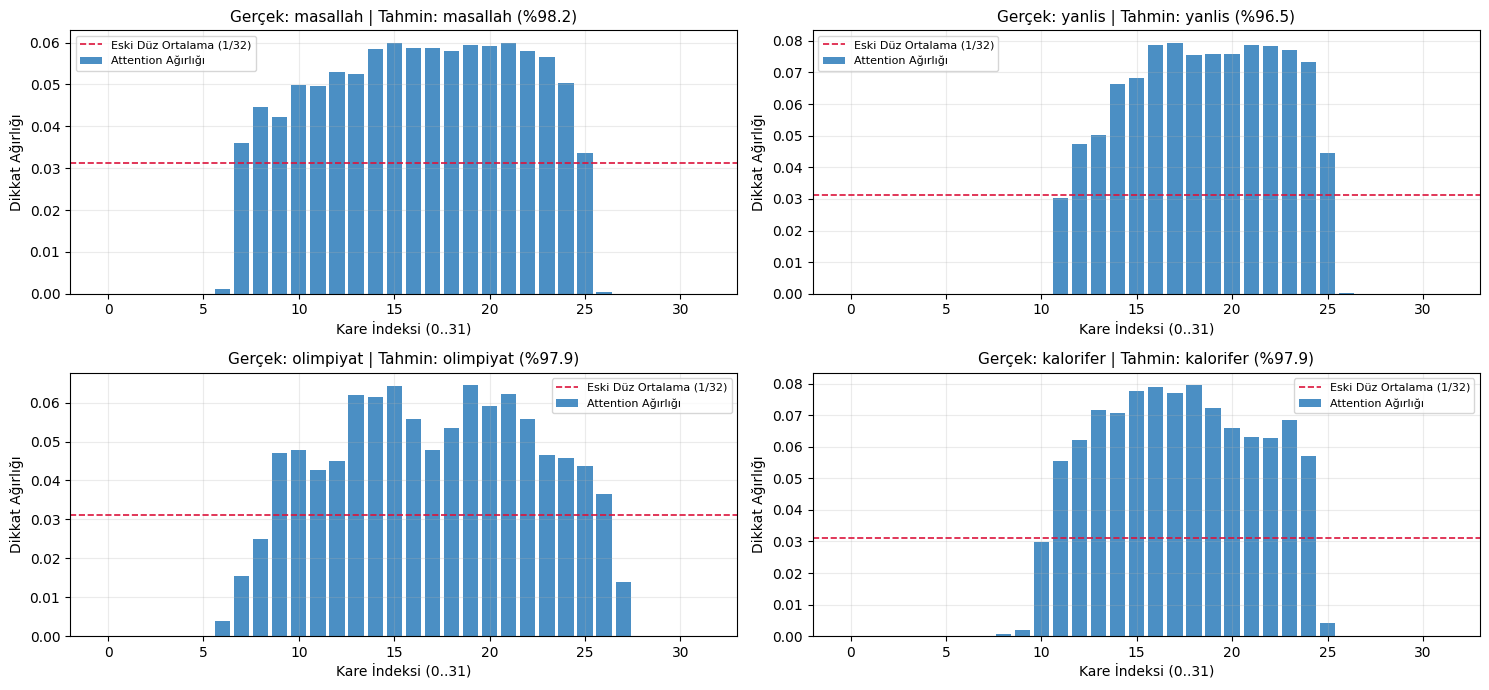

In [17]:
sample_indices = np.random.choice(len(test_ds), 4, replace=False)
fig, axes = plt.subplots(2, 2, figsize=(15, 7))

jetson_model.eval()
with torch.no_grad():
    for ax, idx in zip(axes.flatten(), sample_indices):
        seq_t, true_y = test_ds[idx]
        logits, attn = jetson_model.forward_with_attention(seq_t.unsqueeze(0).to(device))
        probs = torch.softmax(logits, dim=1)[0]
        pred_y = int(probs.argmax().item())
        conf = float(probs[pred_y].item()) * 100.0
        attn_np = attn[0].cpu().numpy()

        ax.bar(np.arange(TARGET_FRAMES), attn_np, color='#2b7bba', alpha=0.85, label='Attention Ağırlığı')
        ax.axhline(1.0 / TARGET_FRAMES, color='crimson', linestyle='--', linewidth=1.2, label='Eski Düz Ortalama (1/32)')
        true_w = class_map.get(int(true_y), '?')
        pred_w = class_map.get(pred_y, '?')
        ax.set_title(f"Gerçek: {true_w} | Tahmin: {pred_w} (%{conf:.1f})", fontsize=11)
        ax.set_xlabel("Kare İndeksi (0..31)")
        ax.set_ylabel("Dikkat Ağırlığı")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [18]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
import subprocess

def record_webcam_colab(webm_path='webcam_raw.webm', mp4_path='webcam_fixed.mp4', duration=3):
    js = Javascript(f'''
    async function recordVideo() {{
        const div = document.createElement('div');
        const info = document.createElement('p');
        info.innerText = '🔴 Kayıt yapılıyor ({duration} sn)... İşareti şimdi yapın!';
        info.style.fontWeight = 'bold';
        info.style.color = '#d93025';
        const video = document.createElement('video');
        video.style.display = 'block';
        video.style.width = '420px';
        video.style.borderRadius = '8px';
        const stream = await navigator.mediaDevices.getUserMedia({{video: {{width: 640, height: 480}}}});
        document.body.appendChild(div);
        div.appendChild(info);
        div.appendChild(video);
        video.srcObject = stream;
        video.muted = true;
        await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        const recorder = new MediaRecorder(stream);
        const chunks = [];
        recorder.ondataavailable = e => chunks.push(e.data);
        recorder.start();
        await new Promise(r => setTimeout(r, {duration * 1000}));
        recorder.stop();
        await new Promise(r => recorder.onstop = r);
        stream.getTracks().forEach(t => t.stop());
        div.remove();

        const blob = new Blob(chunks, {{type: 'video/webm'}});
        const buf = await blob.arrayBuffer();
        const bytes = new Uint8Array(buf);
        let bin = '';
        for (let i = 0; i < bytes.byteLength; i++) bin += String.fromCharCode(bytes[i]);
        return btoa(bin);
    }}
    ''')
    display(js)
    b64_data = eval_js('recordVideo()')
    with open(webm_path, 'wb') as f:
        f.write(b64decode(b64_data))
    subprocess.run(
        ['ffmpeg', '-y', '-i', webm_path, '-r', '30', '-vsync', 'cfr', '-c:v', 'libx264', mp4_path, '-loglevel', 'error'],
        check=True
    )
    return mp4_path


def extract_webcam_clip(mp4_path, mirror_input=False, trim_idle_edges=True):
    cap = cv2.VideoCapture(mp4_path)
    frames_rgb = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        if mirror_input:
            frame = cv2.flip(frame, 1)
        frames_rgb.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()

    if not frames_rgb:
        return np.zeros((TARGET_FRAMES, TOTAL_LM, 3), dtype=np.float32), []

    pose_d = vision.PoseLandmarker.create_from_options(
        vision.PoseLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='pose_landmarker.task'), running_mode=vision.RunningMode.VIDEO)
    )
    face_d = vision.FaceLandmarker.create_from_options(
        vision.FaceLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='face_landmarker.task'), running_mode=vision.RunningMode.VIDEO, num_faces=1)
    )
    hand_d = vision.HandLandmarker.create_from_options(
        vision.HandLandmarkerOptions(base_options=python.BaseOptions(model_asset_path='hand_landmarker.task'), running_mode=vision.RunningMode.VIDEO, num_hands=2, min_hand_detection_confidence=0.35)
    )

    all_lms, hand_active = [], []
    for i, rgb in enumerate(frames_rgb):
        ts = (i + 1) * 33
        mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb)
        pr = pose_d.detect_for_video(mp_img, ts)
        fr = face_d.detect_for_video(mp_img, ts)
        hr = hand_d.detect_for_video(mp_img, ts)
        all_lms.append(pack_frame_landmarks(pr, fr, hr))
        hand_active.append(bool(hr.hand_landmarks))

    pose_d.close(); face_d.close(); hand_d.close()
    all_lms = np.stack(all_lms, axis=0)

    start, end = 0, len(frames_rgb) - 1
    if trim_idle_edges and any(hand_active):
        act = [i for i, ok in enumerate(hand_active) if ok]
        start = max(0, min(act) - 4)
        end   = min(len(frames_rgb) - 1, max(act) + 4)

    seg_lms, seg_rgb = all_lms[start:end + 1], frames_rgb[start:end + 1]
    seg_len = len(seg_lms)
    if seg_len >= TARGET_FRAMES:
        idxs = np.linspace(0, seg_len - 1, TARGET_FRAMES, dtype=int)
    else:
        idxs = np.concatenate([np.arange(seg_len, dtype=int), np.full(TARGET_FRAMES - seg_len, seg_len - 1, dtype=int)])

    sampled_lms = clean_single_sequence(seg_lms[idxs])
    sampled_rgb = [seg_rgb[i] for i in idxs]
    return sampled_lms, sampled_rgb


MIRROR_WEBCAM = False
mp4_file = record_webcam_colab(duration=3)
clip_lms, clip_rgb = extract_webcam_clip(mp4_file, mirror_input=MIRROR_WEBCAM, trim_idle_edges=True)

jetson_model.eval()
with torch.no_grad():
    inp = torch.from_numpy(clip_lms).unsqueeze(0).to(device)
    logits, attn_w = jetson_model.forward_with_attention(inp)
    probs = torch.softmax(logits, dim=1)[0]
    top5 = probs.topk(5)

print("\n🏆 Webcam Top-5 Tahmin Sonucu (Tekil Jetson Modeli):")
for rank in range(5):
    cid = int(top5.indices[rank].item())
    prb = float(top5.values[rank].item()) * 100.0
    print(f"  {rank+1}. {class_map.get(cid, '?'):20s} (%{prb:.1f})")

if clip_rgb:
    show_idx = np.linspace(0, TARGET_FRAMES - 1, 8, dtype=int)
    fig, axes = plt.subplots(1, 8, figsize=(22, 3.2))
    attn_np = attn_w[0].cpu().numpy()
    for ax, fi in zip(axes, show_idx):
        vis_im = clip_rgb[fi].copy()
        h_im, w_im, _ = vis_im.shape
        for (sl, col, rad) in [
            (SLICE_POSE, (255, 60, 60), 4),
            (SLICE_FACE, (255, 220, 0), 2),
            (SLICE_LH,   (0, 200, 255), 3),
            (SLICE_RH,   (50, 255, 80), 3),
        ]:
            for px, py, _ in clip_lms[fi, sl]:
                if abs(px) + abs(py) > 1e-4:
                    cv2.circle(vis_im, (int(px * w_im), int(py * h_im)), rad, col, -1)
        ax.imshow(vis_im)
        ax.set_title(f"F{fi} | Attn:{attn_np[fi]:.2f}", fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

<IPython.core.display.Javascript object>


🏆 Webcam Top-5 Tahmin Sonucu (Tekil Jetson Modeli):
  1. kardes               (%97.5)
  2. misafir              (%0.1)
  3. kopru                (%0.1)
  4. beraber              (%0.0)
  5. akilsiz              (%0.0)


## 7. Jetson Orin Nano Dağıtım Paketi (`ONNX` + `ONNXRuntime` Doğrulaması + `trtexec`)
Bu hücre damıtılmış tekil Jetson modelini dışa aktarır, PyTorch ile ONNX çıktılarının sayısal olarak birebir örtüştüğünü doğrular ve Jetson Orin Nano'ya tek klasör halinde kopyalayabileceğiniz paket dizinini oluşturur.

In [14]:
import json
import shutil
import onnxruntime as ort

model_export = RoboSignFormer(num_classes=NUM_CLASSES, max_len=TARGET_FRAMES).to('cpu').eval()
model_export.load_state_dict(torch.load(JETSON_PT_PATH, map_location='cpu', weights_only=True))

ONNX_PATH   = os.path.join(MODELS_V2_DIR, 'robosignformer_jetson.onnx')
CONFIG_PATH = os.path.join(MODELS_V2_DIR, 'robosignformer_config.json')

dummy_input = torch.randn(1, TARGET_FRAMES, TOTAL_LM, 3, dtype=torch.float32)

export_kwargs = dict(
    input_names=['landmarks_32x80x3'],
    output_names=['class_logits'],
    dynamic_axes={'landmarks_32x80x3': {0: 'batch_size'}, 'class_logits': {0: 'batch_size'}},
    opset_version=17,
)
try:
    torch.onnx.export(model_export, dummy_input, ONNX_PATH, dynamo=False, **export_kwargs)
except TypeError:
    torch.onnx.export(model_export, dummy_input, ONNX_PATH, **export_kwargs)

# PyTorch vs ONNX sayısal tutarlılık doğrulaması
with torch.no_grad():
    pt_out = model_export(dummy_input).numpy()
ort_sess = ort.InferenceSession(ONNX_PATH, providers=['CPUExecutionProvider'])
ort_out  = ort_sess.run(['class_logits'], {'landmarks_32x80x3': dummy_input.numpy()})[0]
max_diff = float(np.max(np.abs(pt_out - ort_out)))

# MediaPipe .task dosyalarını da aynı dağıtım klasörüne kopyala (Jetson'a tek klasör taşımak için)
for task_file in ['pose_landmarker.task', 'face_landmarker.task', 'hand_landmarker.task']:
    shutil.copy2(task_file, os.path.join(MODELS_V2_DIR, task_file))

onnx_size_mb = os.path.getsize(ONNX_PATH) / (1024 * 1024)
export_cfg = {
    "model_name": "RoboSignFormer_Jetson_Student",
    "project": "ROBODOST_Vision",
    "target_hardware": "NVIDIA Jetson Orin Nano",
    "parameters": int(N_PARAMS),
    "onnx_size_mb": round(onnx_size_mb, 2),
    "target_frames": TARGET_FRAMES,
    "total_landmarks": TOTAL_LM,
    "pose_indices": POSE_INDICES,
    "face_indices": FACE_INDICES,
    "bones_52": ALL_BONES,
    "num_classes": NUM_CLASSES,
    "seed_test_top1_mean": round(float(mean_t1), 3),
    "seed_test_top1_std": round(float(std_t1), 3),
    "jetson_student_test_top1": round(float(100.0 * jet_corr1 / total_n), 3),
    "class_map": {str(k): v for k, v in class_map.items()},
}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(export_cfg, f, ensure_ascii=False, indent=2)

print(f"✅ ONNX Doğrulaması Başarılı! Maksimum PyTorch-ONNX farkı: {max_diff:.2e}")
print(f"📦 ONNX Boyutu     : {onnx_size_mb:.2f} MB (FP16 TensorRT motorunda ~{onnx_size_mb/2:.2f} MB)")
print(f"📁 Dağıtım Klasörü : {MODELS_V2_DIR}")
print("\n🔧 Jetson Orin Nano üzerinde TensorRT FP16 motoruna çevirmek için terminal komutu:")
print("   /usr/src/tensorrt/bin/trtexec --onnx=robosignformer_jetson.onnx --saveEngine=robosignformer_fp16.engine --fp16")

/tmp/ipykernel_620/3219011007.py:230: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder    = nn.TransformerEncoder(enc_layer, num_layers=num_layers)
/tmp/ipykernel_620/4197618876.py:20: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_export, dummy_input, ONNX_PATH, dynamo=False, **export_kwargs)


✅ ONNX Doğrulaması Başarılı! Maksimum PyTorch-ONNX farkı: 1.79e-06
📦 ONNX Boyutu     : 6.79 MB (FP16 TensorRT motorunda ~3.39 MB)
📁 Dağıtım Klasörü : /content/drive/MyDrive/AUTSL/models_robosignformer_jetson

🔧 Jetson Orin Nano üzerinde TensorRT FP16 motoruna çevirmek için terminal komutu:
   /usr/src/tensorrt/bin/trtexec --onnx=robosignformer_jetson.onnx --saveEngine=robosignformer_fp16.engine --fp16
